## Вариант 9. Метрики классификации и регрессии — ловушки и правильный выбор

**Цель:** Выбрать метрику и интерпретировать её.

1. Обучите бинарный классификатор на несбалансированных данных. Постройте **ROC-кривую и PR-кривую** вручную (без готовых функций), вычислите AUC-ROC и AUC-PR.

ROC-кривая показывает зависимость TPR (верно классифицируемых объектов положительного класса, ось Y) от FPR (ложных положительно классифицированных объектов негативного класса, ось Х)
$$TPR=\frac{TP}{TP+FN}$$
$$FPR=\frac{FP}{FP+TN}$$
PR-кривая показывает зависимость Precision (верно классифицируемых объектов сради всех классифицированных как положительные, ось Y) от Recall (верно классифицируемых объектов положительного класса, ось X):
$$Precision=\frac{TP}{TP+FP}$$
$$Recall=\frac{TP}{TP+FN}$$
AUC - площадь под кривой\
AUC-ROC - площадь под ROC-кривой\
AUC-PR - площадь под PR-кривой

Для вычисления площадей под кривыми используется метод трапеций, формула которого выглядит так:
$$AUC=\sum_{i=1}^{n-1}\frac{y_i+y_{i+1}}{2}(x_{i+1}-x_i)$$
n - количество точек\
i - номер текущей точки



###Пример:
Есть 6 объектов, у которых известны настоящие классы и есть вероятности принадлежности к классу 1
|Истинный класс|Вероятность класса 1|
|--------------|--------------------|
|1             |0.90                |
|0             |0.80                |
|1             |0.70                |
|0             |0.40                |
|0             |0.30                |
|0             |0.10                |

Все объекты с вероятностью 0.70 и больше относятся к классу 1, остальные - к классу 0\
Матрица ошибок для порого 0.70 имеет следующий вид:
|                  |Истинный класс 1|Истинный класс 0|
|------------------|----------------|----------------|
|Предсказан класс 1|TP = 2          |FP = 1          |
|Предсказан класс 0|FN = 0          |TN = 3          |

Значения метрик получаются такими:
$$TPR=\frac{2}{2+0}=\frac{2}{2}=1$$
$$FPR=\frac{1}{1+3}=\frac{1}{4}=0.25$$
$$Precision=\frac{2}{2+1}=\frac{2}{3}\approx0.667$$
$$Recall=\frac{2}{2+0}=\frac{2}{2}=1$$

В указанных условиях для порога 0.70 для ROC-кривой получена точка (0.25;1), а для PR-кривой получена точка (1;0.667). Аналогично проводятся вычисления метрик и для других значения порогов
|Порог|FPR |TPR|Recall|Precision|
|-----|----|---|------|---------|
|>0.90|0   |0  |0     |1        |
|0.90 |0   |0.5|0.5   |1        |
|0.80 |0.25|0.5|0.5   |0.5      |
|0.70 |0.25|1  |1     |0.667    |
|0.40 |0.5 |1  |1     |0.5      |
|0.30 |0.75|1  |1     |0.4      |
|0.10 |1   |1  |1     |0.333    |

Используя формулу метода трапеций, получаются следующие значения для AUC-ROC и AUC-PR:
$$
AUC-ROC=\frac{0+0.5}{2}(0-0)+\frac{0.5+0.5}{2}(0.25-0)+\frac{0.5+1}{2}(0.25-0.25)+\frac{1+1}{2}(0.5-0.25)+\frac{1+1}{2}(0.75-0.5)+\frac{1+1}{2}(1-0.75)=0+0.125+0+0.25+0.25+0.25=0.875
$$
$$
AUC-PR=\frac{1+1}{2}(0.5-0)+\frac{1+0.5}{2}(0.5-0.5)+\frac{0.5+0.667}{2}(1-0.5)+\frac{0.667+0.5}{2}(1-1)+\frac{0.5+0.4}{2}(1-1)+\frac{0.4+0.333}{2}(1-1)\approx0.5+0+0.2917+0+0+0=0.7917
$$

Для эксперимента использована логистическая регрессия. С помощью неё можно определить вероятность принадлежности объекта к положительному классу.\
Для эксперимента будет создан набор из 2000 объектов с 10 признаками. 95% объектов будут относиться к классу 0, 5% будут относиться к классу 1



In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import pandas as pd

In [ ]:
X, y = datasets.make_classification(
  n_samples=2000,
  n_features=10,
  n_informative=6,
  n_redundant=2,
  weights=[0.95, 0.05],
  flip_y=0,
  random_state=42
)
print("Класс 0:", np.sum(y == 0))
print("Класс 1:", np.sum(y == 1))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
y_pred = lr.predict_proba(X_test)
print()
print("Обучающая выборка:", np.bincount(y_train))
print("Тестовая выборка:", np.bincount(y_test))

roc = []
pr = []
thresholds = np.unique(y_pred[:, 1])[::-1]
thresholds = np.insert(thresholds, 0, np.inf)
for tr in thresholds:
  y_p = (y_pred[:, 1] >= tr).astype(int)
  TP = np.sum((y_test == 1) & (y_p == 1))
  FP = np.sum((y_test == 0) & (y_p == 1))
  TN = np.sum((y_test == 0) & (y_p == 0))
  FN = np.sum((y_test == 1) & (y_p == 0))
  TPR = TP / (TP + FN)
  FPR = FP / (FP + TN)
  Precision = TP / (TP + FP) if TP + FP > 0 else 1
  Recall = TP / (TP + FN)
  roc += [[FPR, TPR]]
  pr += [[Recall, Precision]]
roc = np.array(roc)
pr = np.array(pr)

def calcauc(points):
  n = len(points)
  auc = 0
  for i in range(n-1):
    auc += ((points[i,1]+points[i+1,1])/2)*(points[i+1,0]-points[i,0])
  return auc
auc_roc = calcauc(roc)
auc_pr = calcauc(pr)
print()
print("AUC-ROC:", round(auc_roc, 4))
print("AUC-PR:", round(auc_pr, 4))

Класс 0: 1900
Класс 1: 100

Обучающая выборка: [1330   70]
Тестовая выборка: [570  30]

AUC-ROC: 0.9114
AUC-PR: 0.5095


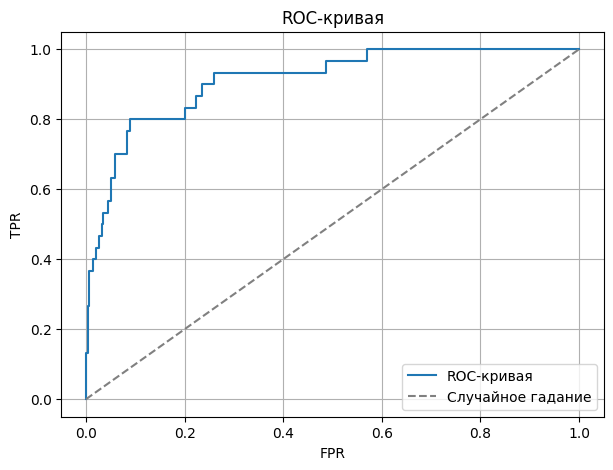

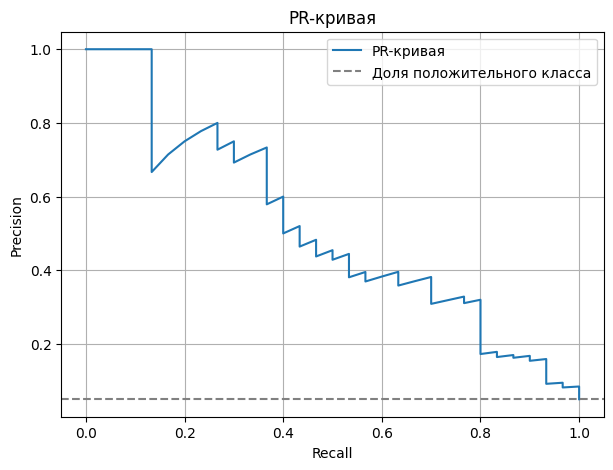

In [ ]:
plt.figure(figsize=(7, 5))
plt.plot(roc[:, 0], roc[:, 1], label=f"ROC-кривая")
plt.plot([0, 1], [0, 1], '--', color='gray', label='Случайное гадание')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC-кривая')
plt.grid()
plt.legend()
plt.show()


plt.figure(figsize=(7, 5))
plt.plot(pr[:, 0], pr[:, 1], label=f"PR-кривая")
plt.axhline(np.mean(y_test), linestyle='--', color='gray', label='Доля положительного класса')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR-кривая')
plt.grid()
plt.legend()
plt.show()


Первый графиик показывает, что ROC-кривая строится гораздо выше линии случайного классификатора. Кривая находится близко к левому углу, а значит она хорошо разделяет классы. Полученное значение площади под кривой в 0.9114 подтверждает это

Второй график показывает, что PR-кривая находится выше уровня, показывающего долю положительных ответов выборки. Значит модель обнаруживает положительный класс лучше случайного классификатора. При этом график находится далековато от правого угла, т.к. при уменьшении порога классификации растёт число как новых положительных объектов, так и ложноположительных срабатываний. Полученное значение площади под кривой в 0.5095 подтверждает сказанное

Модель неплохо справляется с разделением классов и обнаружением части положительных объектов. Но с увеличением полноты приходится допускать больше ложноположительных предсказаний

2. Покажите на примере, что **высокий AUC-ROC может скрывать плохой recall** на редком классе. Приведите численный пример.

###Пример:
Рассмотрим набор из 20 объектов, где 19 из них будут относится к классу 0 и 1 из них будет относится к классу 1

Модель выдаёт такие результаты:
|Истинный класс|Вероятность класса 1|Количество объектов|
|--------------|--------------------|-------------------|
|1             |0.40                |1                  |
|0             |0.60                |1                  |
|0             |0.10                |18                 |

Если выбрать порог как 0.5, то матрица ошибок будет такой:
|                  |Истинный класс 1|Истинный класс 0|
|------------------|----------------|----------------|
|Предсказан класс 1|TP = 0          |FP = 1          |
|Предсказан класс 0|FN = 1          |TN = 18         |

$$Recall=\frac{TP}{TP+FN}=\frac{0}{0+1}=0$$

|Порог|FPR |TPR|
|-----|----|---|
|>0.60|0   |0  |
|0.60 |1/19|0  |
|0.40 |1/19|1  |
|0.10 |1   |1  |

Используя формулу метода трапеций, получается следующее значения для AUC-ROC:
$$AUC_{ROC}=\frac{0+0}{2}(\frac{1}{19}-0)
+\frac{0+1}{2}(\frac{1}{19}-\frac{1}{19})
+\frac{1+1}{2}(1-\frac{1}{19})=0+0+\frac{18}{19}\approx0.9474$$

Из вычислений получилось, что при высоком AUC-ROC=0.9474 значение Recall составляет 0

Для эксперимента я использую результаты классификатора из первого пункта\
Вычисление Recall выполню при пороге 0.5

In [ ]:
threshold = 0.5
y_p = (y_pred[:, 1] >= threshold).astype(int)
TP = np.sum((y_test == 1) & (y_p == 1))
FP = np.sum((y_test == 0) & (y_p == 1))
TN = np.sum((y_test == 0) & (y_p == 0))
FN = np.sum((y_test == 1) & (y_p == 0))
recall = TP / (TP + FN)
print("AUC-ROC:", round(auc_roc, 4))
print("Recall:", round(recall, 4))

trs = np.linspace(0, 1, 101)
recalls = []
for tr in trs:
  y_p = (y_pred[:, 1] >= tr).astype(int)
  tp = np.sum((y_test == 1) & (y_p == 1))
  fn = np.sum((y_test == 1) & (y_p == 0))
  recalls.append(tp / (tp + fn))

AUC-ROC: 0.9114
Recall: 0.3667


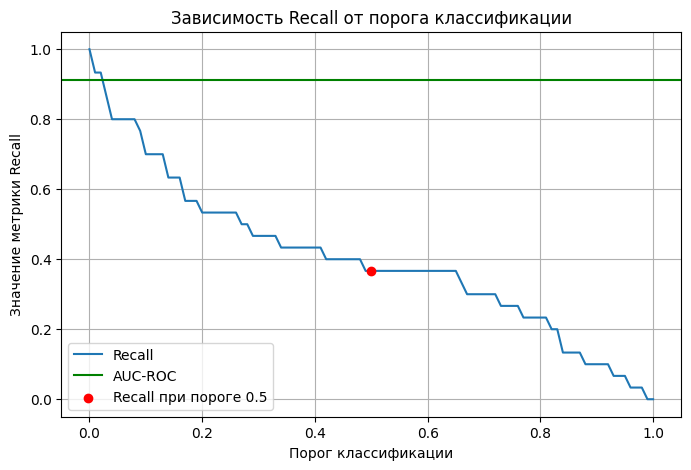

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(trs, recalls, label='Recall')
plt.axhline(auc_roc, color='green', label=f'AUC-ROC')
plt.scatter(threshold, recall, color='red', zorder=3, label=f'Recall при пороге 0.5')

plt.xlabel('Порог классификации')
plt.ylabel('Значение метрики Recall')
plt.title('Зависимость Recall от порога классификации')
plt.grid()
plt.legend()
plt.show()

На графике видно, что при увеличении порога Recall уменьшается. При пороге 0.5 значение Recall составляет 0.3667. Значит, модель правильно обнаруживает только 11 из 30 положительных объектов и пропускает остальные 19. При этом AUC-ROC составляет 0.9114
Значит, несмотря на хорошую способность модели различать классы, при пороге выбранном пороге 0.5 модель пропускает большую часть объектов редкого положительного класса

3. Исследуйте **выбор порога**: постройте зависимость precision/recall/F1 от порога, найдите оптимальный по F1 и по «стоимости ошибок» (задайте матрицу стоимостей).

F1 это гармоническое среднее Precision и Recall:
$$F1=\frac{2\cdot Precision\cdot Recall}{Precision+Recall}$$


###Пример:
Рассмотрим пример из 7 объектов
|Истинный класс|Вероятность класса 1|
|--------------|--------------------|
|1             |0.90                |
|0             |0.80                |
|0             |0.70                |
|0             |0.60                |
|0             |0.50                |
|1             |0.40                |
|0             |0.30                |

Пусть порог равен 0.90:\
Модель правильно обнаруживает один положительный объект и пропускает второй. Ложноположительных предсказаний нет\
TP = 1\
FP = 0\
FN = 1\
$$Precision=\frac{TP}{TP+FP}=\frac{1}{1+0}=1$$
$$Recall=\frac{TP}{TP+FN}=\frac{1}{1+1}=0.5$$
$$F1=\frac{2\cdot Precision\cdot Recall}{Precision+Recall}
=\frac{2\cdot1\cdot0.5}{1+0.5}\approx0.6667$$

Пусть порог равен 0.40:\
Модель правильно обнаруживает оба положительных объекта, но ошибочно относит к положительному классу ещё четыре отрицательных объекта
TP = 2\
FP = 4\
FN = 0\
$$Precision=\frac{TP}{TP+FP}=\frac{2}{2+4}\approx0.3333$$
$$Recall=\frac{TP}{TP+FN}=\frac{2}{2+0}=1$$

$$F1=\frac{2\cdot Precision\cdot Recall}{Precision+Recall}
=\frac{2\cdot\frac{1}{3}\cdot1}{\frac{1}{3}+1}=0.5$$

Составлю таблицу показателей для всех порогов:
|Порог|Precision|Recall|F1   |
|-----|---------|------|-----|
|>0.90|0        |0     |0    |
|0.90 |1.000    |0.500 |0.667|
|0.80 |0.500    |0.500 |0.500|
|0.70 |0.333    |0.500 |0.400|
|0.60 |0.250    |0.500 |0.333|
|0.50 |0.200    |0.500 |0.286|
|0.40 |0.333    |1.000 |0.500|
|0.30 |0.286    |1.000 |0.444|

Макисмальное значение F1 достигается при пороге 0.90

Пусть для матрицы стоимостей ошибок правильные предсказания имеют нулевую стоимость, за каждую ошибку FP начисляется одно значение, а за FN начисляется 10
|Истинный класс|Предсказан класс 0|Предсказан класс 1|
|--------------|------------------|------------------|
|0             |TN: 0             |FP: 1             |
|1             |FN: 10            |TP: 0             |

Таблица стоимости ошибок для всех порогов:
|Порог|FP|FN|Стоимость ошибок|
|-----|--|--|----------------|
|>0.90|0 |2 |20              |
|0.90 |0 |1 |10              |
|0.80 |1 |1 |11              |
|0.70 |2 |1 |12              |
|0.60 |3 |1 |13              |
|0.50 |4 |1 |14              |
|0.40 |4 |0 |4               |
|0.30 |5 |0 |5               |

Минимальная стоимость ошибок достигается при пороге 0.4

Для экспериента использую результат логистической регрессии из первого пункта

Для ошибок будут начислять такие же значения, как в аналитической части: правильные предсказания имеют нулевую стоимость, за каждую ошибку FP начисляется одно значение, а за FN начисляется 10

In [ ]:
trs = np.unique(y_pred[:, 1])
precisions = []
recalls = []
f1_values = []
costs = []

for tr in trs:
  y_p = (y_pred[:, 1] >= tr).astype(int)
  TP = np.sum((y_test == 1) & (y_p == 1))
  FP = np.sum((y_test == 0) & (y_p == 1))
  TN = np.sum((y_test == 0) & (y_p == 0))
  FN = np.sum((y_test == 1) & (y_p == 0))
  Precision = TP / (TP + FP) if TP + FP > 0 else 1
  Recall = TP / (TP + FN)
  F1 = 2 * Precision * Recall / (Precision + Recall) if Precision + Recall > 0 else 0
  cost = FP + 10 * FN
  precisions.append(Precision)
  recalls.append(Recall)
  f1_values.append(F1)
  costs.append(cost)

bestf1idx = f1_values.index(max(f1_values))
bestcostidx = costs.index(min(costs))

print("Оптимальный порог по F1:", round(trs[bestf1idx], 4))
print("Precision:", round(precisions[bestf1idx], 4))
print("Recall:", round(recalls[bestf1idx], 4))
print("Максимальный F1:", round(f1_values[bestf1idx], 4))
print()
print("Оптимальный порог по стоимости ошибки:", round(trs[bestcostidx], 4))
print("Минимальная стоимость:", costs[bestcostidx])
print("Precision:", round(precisions[bestcostidx], 4))
print("Recall:", round(recalls[bestcostidx], 4))
print("F1:", round(f1_values[bestcostidx], 4))

Оптимальный порог по F1: 0.1309
Precision: 0.3818
Recall: 0.7
Максимальный F1: 0.4941

Оптимальный порог по стоимости ошибки: 0.0888
Минимальная стоимость: 111
Precision: 0.32
Recall: 0.8
F1: 0.4571


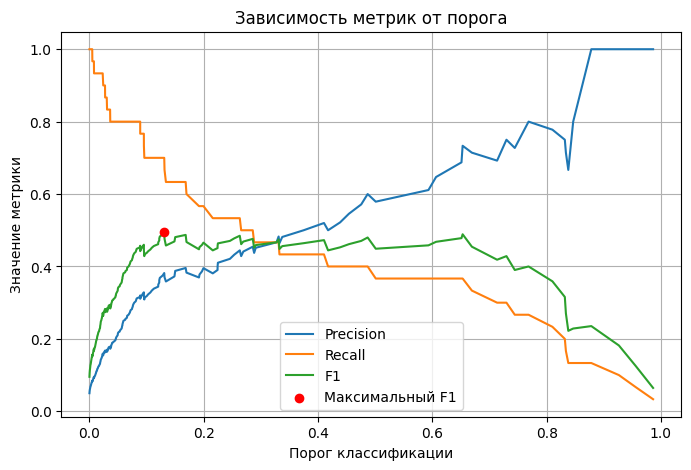

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(trs, precisions, label='Precision')
plt.plot(trs, recalls, label='Recall')
plt.plot(trs, f1_values, label='F1')
plt.scatter(trs[bestf1idx], f1_values[bestf1idx], color='red', zorder=3, label=f'Максимальный F1')
plt.xlabel('Порог классификации')
plt.ylabel('Значение метрики')
plt.title('Зависимость метрик от порога')
plt.grid()
plt.legend()
plt.show()


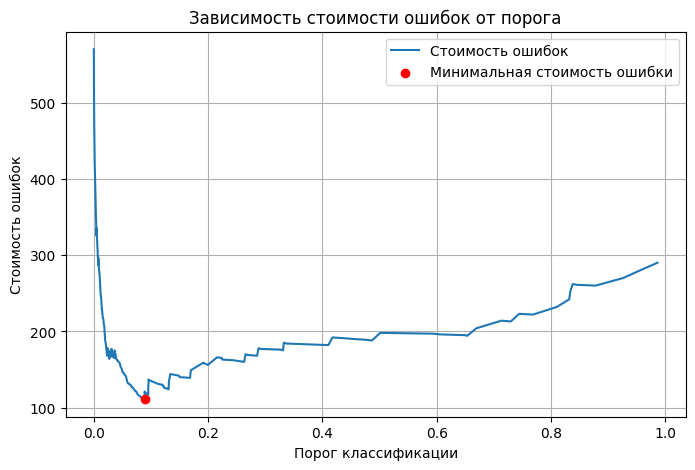

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(trs, costs, label='Стоимость ошибок')
plt.scatter(trs[bestcostidx], costs[bestcostidx], color='red', zorder=3, label=f'Минимальная стоимость ошибки')
plt.xlabel('Порог классификации')
plt.ylabel('Стоимость ошибок')
plt.title('Зависимость стоимости ошибок от порога')
plt.grid()
plt.legend()
plt.show()

При увеличении порога Recall уменьшается, тогда как Precision возрастает. F1 достигает максимум при определённом пороге - там где достигается наилучший баланс между Precision и Recall\
При низких порогах возникает много ложноположительных ошибок, из-за чего кривая на втором графике сначала идет вниз. С увеличением порога увеличивается число пропущенных положительных объектов и кривая стремится вверх\
Оптимальный порог зависит от выбранного критерия: баланса метрик или стоимости ошибки классификации

4. **Многоклассовая задача:** сравните macro-, micro-, weighted-усреднение F1. Приведите пример, где они дают разные выводы.

Три способа усреднения:\
Macro-F1 - среднее арифметическое F1 всех классов\
Micro-F1 - F1, вычисленный после суммирования TP, FP и FN по всем классам\
Weighted-F1 - среднее F1 с учётом количества объектов каждого класса

###Пример:
Рассмотрим 10 объектов 3 классов (Класс 0 - 8 объектов, Класс 1 - 1 объект, Класс 2 - 1 объект)

Классификатор A: все объекты относит к наиболее распространённому классу 0
|Предсказанный класс/Истинный класс|0|1|2|
|----------------------------------|-|-|-|
|0                                 |8|1|1|
|1                                 |0|0|0|
|2                                 |0|0|0|

Класс 0: TP = 8, FP = 2, FN = 0.
$$F1,0=\frac{2\cdot8}{2\cdot8+2+0}=\frac{16}{18}\approx0.8889$$

Класс 1: TP = 0, FP = 0, FN = 1.
$$F1,1=\frac{2\cdot0}{2\cdot0+0+1}=0$$

Класс 2: TP = 0, FP = 0, FN = 1.
$$F1,2=\frac{2\cdot0}{2\cdot0+0+1}=0$$

Macro-F1:
$$Macro=\frac{F1_0+F1_1+F1_2}{3}=\frac{0.8889+0+0}{3}\approx0.2963$$

Micro-F1:
$$TP=8+0+0=8$$
$$FP=2+0+0=2$$
$$FN=0+1+1=2$$
$$Micro=\frac{2\cdot8}{2\cdot8+2+2}=0.8$$

Weighted-F1:

$$Weighted=\frac{8\cdot F1_0+1\cdot F1_1+1\cdot F1_2}{10}=\frac{8\cdot0.8889+1\cdot0+1\cdot0}{10}\approx0.7111$$


Классификатор B: правильно обнаруживает оба редких класса, но допускает много ошибок при классификации объектов класса 0
|Предсказанный класс/Истинный класс|0|1|2|
|----------------------------------|-|-|-|
|0                                 |4|0|0|
|1                                 |3|1|0|
|2                                 |1|0|1|

Класс 0: TP = 4, FP = 0, FN = 4.
$$F1_0=\frac{2\cdot4}{2\cdot4+0+4}=\frac{8}{12}\approx0.6667$$

Класс 1: TP = 1, FP = 3, FN = 0.
$$F1_1=\frac{2\cdot1}{2\cdot1+3+0}=\frac{2}{5}=0.4$$

Класс 2: TP = 1, FP = 1, FN = 0.
$$F1_2=\frac{2\cdot1}{2\cdot1+1+0}=\frac{2}{3}\approx0.6667$$

Macro-F1:
$$Macro=\frac{0.6667+0.4+0.6667}{3}\approx0.5778$$

Micro-F1:
$$TP=4+1+1=6$$
$$FP=0+3+1=4$$
$$FN=4+0+0=4$$
$$Micro=\frac{2\cdot6}{2\cdot6+4+4}=0.6$$

Weighted-F1:

$$Weighted=\frac{8\cdot0.6667+1\cdot0.4+1\cdot0.6667}{10}\approx0.64$$

По Macro-F1 лучше классификатор B\
По Micro-F1 и Weighted-F1 лучше классификатор A



















































Для эксперимента создаётся выборка из 900 объектов с тремя классами. Объекты распределены по классам в пропорции 80%, 15% и 5%\
Используются 2 классификатора из аналитической части: классификатор А (все объекты относятся к наиболее распространённому классу 0) и классификатор B (использует логистическую регерессию с повышенными весами для редких классов)

In [ ]:
X, y = datasets.make_classification(
    n_samples=900,
    n_features=10,
    n_informative=6,
    n_redundant=2,
    n_classes=3,
    weights=[0.8, 0.15, 0.05],
    flip_y=0,
    random_state=42
)

print("Класс 0:", np.sum(y == 0))
print("Класс 1:", np.sum(y == 1))
print("Класс 2:", np.sum(y == 2))

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)

lr = LogisticRegression(max_iter=1000, class_weight='balanced')
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

predictions = [np.zeros_like(y_test), y_pred]
results = []

for i in range(2):
  y_p = predictions[i]
  f1_values = []
  TP_sum = 0
  FP_sum = 0
  FN_sum = 0
  weighted_sum = 0
  for cls in range(3):
      TP = np.sum((y_test == cls) & (y_p == cls))
      FP = np.sum((y_test != cls) & (y_p == cls))
      FN = np.sum((y_test == cls) & (y_p != cls))
      F1 = 2*TP/(2*TP+FP+FN) if 2*TP+FP+FN > 0 else 0
      f1_values.append(F1)
      TP_sum += TP
      FP_sum += FP
      FN_sum += FN
      weighted_sum += F1 * np.sum(y_test == cls)
  macro = sum(f1_values) / 3
  micro = 2*TP_sum/(2*TP_sum+FP_sum+FN_sum)
  weighted = weighted_sum / len(y_test)
  results.append([macro, micro, weighted])

  print("F1 по классам:", np.round(f1_values, 4))
  print("Macro-F1:", round(macro, 4))
  print("Micro-F1:", round(micro, 4))
  print("Weighted-F1:", round(weighted, 4))
  print()

Класс 0: 721
Класс 1: 135
Класс 2: 44
F1 по классам: [0.8889 0.     0.    ]
Macro-F1: 0.2963
Micro-F1: 0.8
Weighted-F1: 0.7111

F1 по классам: [0.7895 0.2292 0.2812]
Macro-F1: 0.4333
Micro-F1: 0.6296
Weighted-F1: 0.6799



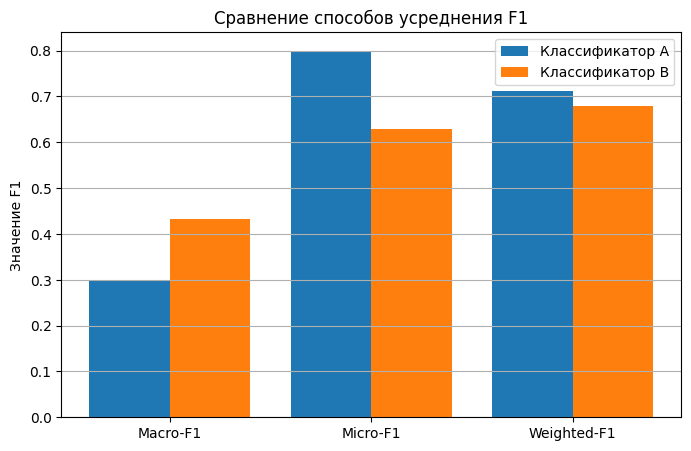

In [ ]:
x = np.arange(3)
plt.figure(figsize=(8, 5))
plt.bar(x - 0.2, results[0], width=0.4, label='Классификатор A')
plt.bar(x + 0.2, results[1], width=0.4, label='Классификатор B')
plt.xticks(x, ['Macro-F1', 'Micro-F1', 'Weighted-F1'])
plt.ylabel('Значение F1')
plt.title('Сравнение способов усреднения F1')
plt.grid(axis='y')
plt.legend()
plt.show()

По полученным результатам видно, что классификатор B лучше оп Macro-F1 из-за лучшего распознавания редких классов. По меркам Micro-F1 и Weighted-F1 лучше классификатор А из-за постоянного предсказывания наиболее распространённого класса

Разные способы усреднения F1 приводят к разным выводам о качестве классификаторов

5. **Регрессия:** сравните MSE, RMSE, MAE, MAPE, R² на данных с разным масштабом и выбросами. Покажите, где MAPE «ломается» (нули/малые значения).

Для оценки качества регрессии используются следующие метрики:

MSE - среднее значение квадратов ошибок
$$MSE=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2$$

RMSE - квадратный корень из MSE
$$RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}$$

MAE - среднее абсолютное значение ошибок
$$MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|$$

MAPE - средняя абсолютная процентная ошибка.
$$MAPE=\frac{100}{n}\sum_{i=1}^{n}|\frac{y_i-\hat{y}_i}{y_i}|$$

R² - показывает, насколько предсказания лучше или хуже использования среднего значения реальных данных.

$$R^2=1-\frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{n}(y_i-\bar{y})^2}$$

$y_i$ - реальное значение, $\hat{y}_i$ - предсказанное значение, $\bar{y}$ - среднее реальных значений

###Пример:

Рассмотрим 5 объектов с известными реальными и предсказанными значениями

|Объект|Реальное значение|Предсказанное значение|Абсолютная ошибка|
|------|-----------------|----------------------|-----------------|
|1     |10               |12                    |2                |
|2     |20               |18                    |2                |
|3     |30               |33                    |3                |
|4     |40               |37                    |3                |
|5     |50               |52                    |2                |

MSE:
$$MSE=\frac{(10-12)^2+(20-18)^2+(30-33)^2+(40-37)^2+(50-52)^2}{5}=\frac{4+4+9+9+4}{5}=6$$

RMSE:
$$RMSE=\sqrt{6}\approx2.4495$$

MAE:
$$MAE=\frac{2+2+3+3+2}{5}=2.4$$

MAPE:
$$MAPE=\frac{100}{5}(\frac{2}{10}+\frac{2}{20}+\frac{3}{30}+\frac{3}{40}+\frac{2}{50})=\frac{100}{5}(0.2+0.1+0.1+0.075+0.04)=10.3\%$$

R²:

$$\bar{y}=\frac{10+20+30+40+50}{5}=30$$

$$R^2=1-\frac{4+4+9+9+4}{(10-30)^2+(20-30)^2+(30-30)^2+(40-30)^2+(50-30)^2}=1-\frac{30}{1000}=0.97$$

####Проблема MAPE:
Проблема MAPE в том, что MAPE зависит не только от абсолютной ошибки, но и от величины реального значения

Если реальное значение равно 0.01, а предсказанное - 2.01, то абсолютная ошибка составляет 2, а относительная ошибка равна:
$$|\frac{0.01-2.01}{0.01}|\cdot100=20000\%$$

Если реальное значение равно нулю, то вычисление невозможно из-за деления на ноль:
$$|\frac{0-2}{0}|\cdot100$$


Для эксперимента создадим набор из 10 реальных и предсказанных значений\
Будет проведено 3 эксперимента:
1. Увеличение масштаб данных в 10 раз
2. Добавление выброса в реальные значения
3. Исследование поведения MAPE при очень маленьких и нулевых значениях

In [ ]:
y = np.array([10, 20, 30, 40, 50, 60, 70, 80, 90, 100], dtype=float)
y_pred = np.array([12, 18, 33, 37, 52, 58, 73, 77, 92, 98], dtype=float)

def metrics(y, y_pred):
    mse = np.mean((y - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae = np.mean(np.abs(y - y_pred))
    if np.all(y != 0):
        mape = 100*np.mean(np.abs((y - y_pred) / y))
    else:
        mape = None
    r2 = 1 - np.sum((y - y_pred)**2) / np.sum((y - np.mean(y))**2)
    return mse, rmse, mae, mape, r2

In [ ]:
base = metrics(y, y_pred)
scaled = metrics(y*10, y_pred*10)
names = ['MSE', 'RMSE', 'MAE', 'MAPE', 'R²']

for i in range(5):
    print(names[i], ": было", round(base[i], 4), "стало", round(scaled[i], 4))

MSE : было 6.0 стало 600.0
RMSE : было 2.4495 стало 24.4949
MAE : было 2.4 стало 24.0
MAPE : было 6.7091 стало 6.7091
R² : было 0.9927 стало 0.9927


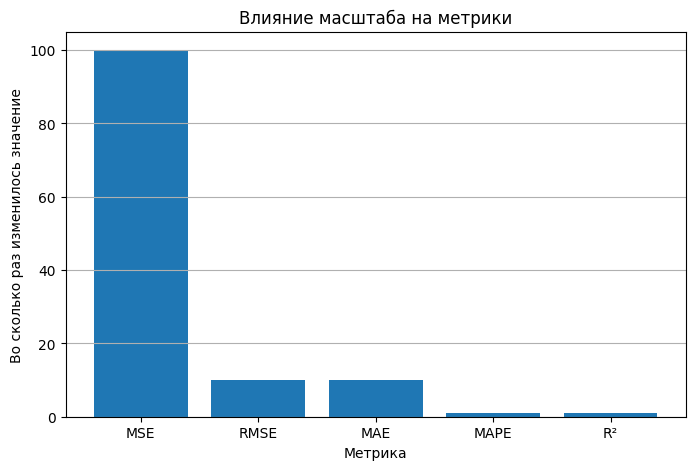

In [ ]:
plt.figure(figsize=(8, 5))
plt.bar(names, [scaled[i] / base[i] for i in range(5)])
plt.xlabel('Метрика')
plt.ylabel('Во сколько раз изменилось значение')
plt.title('Влияние масштаба на метрики')
plt.grid(axis='y')
plt.show()

На графике четко видно, что при увеличении масштаба MSE возрастает в 100 раз, RMSE и MAE возрастают в 10 раз, MAPE и R² не изменилось

Значит, при одинаковом масштабировании реальных и предсказанных значений MSE, RMSE и MAE зависят от масштаба данных, а MAPE и R² не зависят

In [ ]:
y_outlier = y.copy()
y_outlier[-1] = 250
outlier = metrics(y_outlier, y_pred)

for i in range(5):
    print(names[i], ": было", round(base[i], 4), "стало", round(outlier[i], 4))

MSE : было 6.0 стало 2316.0
RMSE : было 2.4495 стало 48.1248
MAE : было 2.4 стало 17.4
MAPE : было 6.7091 стало 12.5891
R² : было 0.9927 стало 0.4486


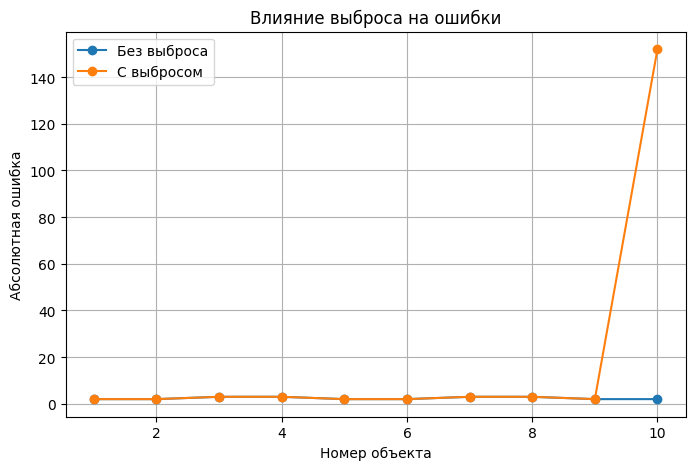

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), np.abs(y - y_pred), marker='o', label='Без выброса')
plt.plot(range(1, 11), np.abs(y_outlier - y_pred), marker='o', label='С выбросом')
plt.xlabel('Номер объекта')
plt.ylabel('Абсолютная ошибка')
plt.title('Влияние выброса на ошибки')
plt.grid()
plt.legend()
plt.show()

На графике четко видно, что добавление одного выброса приводит к резкому увеличению ошибки для отдельного объекта. Если смотреть на полученные значения, сильно возрастают УЧИТЫВАЮЩИЕ КВАДРАТЫ ОШИБОК MSE и RMSE, а значение R² сильно снижается

In [ ]:
values = [10, 1, 0.1, 0.01]
mape_values = []

for value in values:
    y_small = y.copy()
    y_pred_small = y_pred.copy()
    y_small[0] = value
    y_pred_small[0] = value + 2
    mape = metrics(y_small, y_pred_small)[3]
    mape_values.append(mape)

    print("Реальное значение:", value)
    print("MAPE:", round(mape, 4))
    print()

y_small[0] = 0
y_pred_small[0] = 2
if metrics(y_small, y_pred_small)[3] is None:
    print("При нулевом реальном значении MAPE не определена")


Реальное значение: 10
MAPE: 6.7091

Реальное значение: 1
MAPE: 24.7091

Реальное значение: 0.1
MAPE: 204.7091

Реальное значение: 0.01
MAPE: 2004.7091

При нулевом реальном значении MAPE не определена


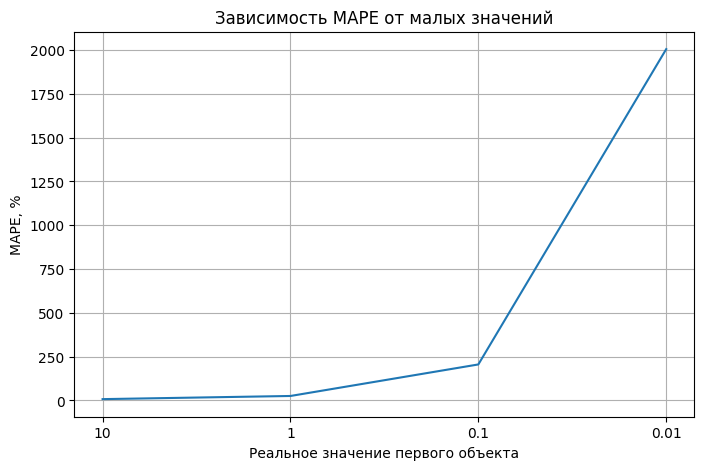

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot([str(v) for v in values], mape_values)
plt.xlabel('Реальное значение первого объекта')
plt.ylabel('MAPE, %')
plt.title('Зависимость MAPE от малых значений')
plt.grid()
plt.show()

На графике четко видно, что уменьшение реализного значения заставляет MAPE резко возрастать, хотя абсолютная ошибка всегда одна и та же. Чем ближе к нулю, тем больше увеличивается значение MAPE, а в самом нуле из-за деления на ноль ее вычислить невозможно

Три проведённых экспермиента показали, что метрики регрессии по-разному реагируют на разные особенности данных. Выбор правильной метрики регрессии должен учитывать масштаб данных, наличие выбросов и возможность появления нулевых и околонулевых значений

#Выводы (с ответами на вопросы варианта)

В процессе работы я подтвердил, что качество модели нельзя объективно оценить по одному показателю. Различные  метрики учитывают различные аспекты модели, так что выосокое значение одной из них не всегда означает, что модель хорошо справляется со своей задачей. Для получения полной оценки необзодимо учитывать особенности данных, характер возможных ошибок и их влияние на конечный результат

Выбор метрики должен зависеть от целей бизнес-задачи. Если важно обнаружить как можно больше значиымх событий, важно следить за показателями Recall; если необходимо снизить количество ложных срабатываний - тут важную роль играет Precision. Некоторые задачи требуют учитывать одновременно несколько показателей и стоимость различных ошибок. В любой задаче наиболее подходящей будет та метрика, что лучше удовлетворяет практическим требованиям к работе модели

Accuracy при этом часто оказывает недостаточной для оценки качества классификации. Она отражает только общую долю правильных предсказаний и не показывает, какие ошибки модель допустила. Ярким примером этому являются несбалансированные классы. Правильное распознавание большинства объектов увеличивает значений Acuuracy, при том что редкие классы обрабатываются плохо. Эту метрику следует рассматривать лишь в комплекте с другими метриками для более полной оценки модели